In [1]:
import pandas as pd
import numpy as np
import sklearn

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-Learn version:", sklearn.__version__)
print("Environment siap digunakan!")

Pandas version: 3.0.6
NumPy version: 2.5.3
Scikit-Learn version: 1.9.1
Environment siap digunakan!


# Project Machine Learning - SDGs 3: Good Health and Well-Being
## Prediksi Risiko Penyakit Jantung menggunakan Algoritma Klasifikasi

* **Topik SDGs:** Target 3.4 - Mengurangi angka kematian akibat penyakit tidak menular melalui pencegahan dan penanganan.
* **Tujuan Project:** Membandingkan 2 algoritma Machine Learning (Logistic Regression, K-Neighbors) untuk memprediksi risiko penyakit jantung berdasarkan data klinis pasien.
* **Dataset:** Heart Failure Prediction Dataset (Kaggle)

### Import Library

In [9]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, f1_score, classification_report, recall_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

import joblib

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Semua library berhasil di-import!")

Semua library berhasil di-import!


### Import Data

In [13]:
try:
    df = pd.read_csv('../dataset/heart.csv')
    print("Dataset berhasil dibaca!")
except FileNotFoundError:
    df = pd.read_csv('dataset/heart.csv')
    print("Dataset berhasil dibaca dari root folder!")

n = len(df)
tengah = n // 2

df.iloc[tengah]

Dataset berhasil dibaca!


Age                41
Sex                 M
ChestPainType     ASY
RestingBP         104
Cholesterol         0
FastingBS           0
RestingECG         ST
MaxHR             111
ExerciseAngina      N
Oldpeak           0.0
ST_Slope           Up
HeartDisease        0
Name: 459, dtype: object

### Print Detail Data Mentah

In [4]:
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")
print("\n--- Tipe Data dan Informasi Non-Null ---")
df.info()

Jumlah Baris: 918
Jumlah Kolom: 12

--- Tipe Data dan Informasi Non-Null ---
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


### Print Deskripsi Kolom

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


### Buat Visualisasi Data berdasarkan Jumlah Pasien

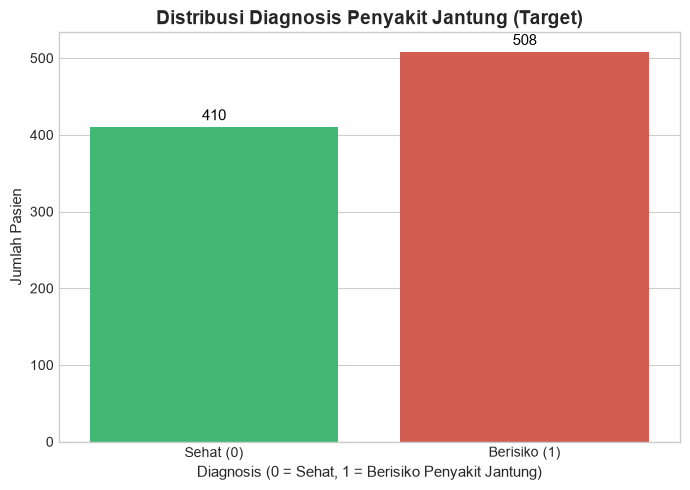

In [6]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(x='HeartDisease',hue='HeartDisease', legend=False, data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('Distribusi Diagnosis Penyakit Jantung (Target)', fontsize=14, fontweight='bold')
plt.xlabel('Diagnosis (0 = Sehat, 1 = Berisiko Penyakit Jantung)', fontsize=11)
plt.ylabel('Jumlah Pasien', fontsize=11)
plt.xticks([0, 1], ['Sehat (0)', 'Berisiko (1)'])

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

### Buat Visualisasi Data berdasarkan Umur

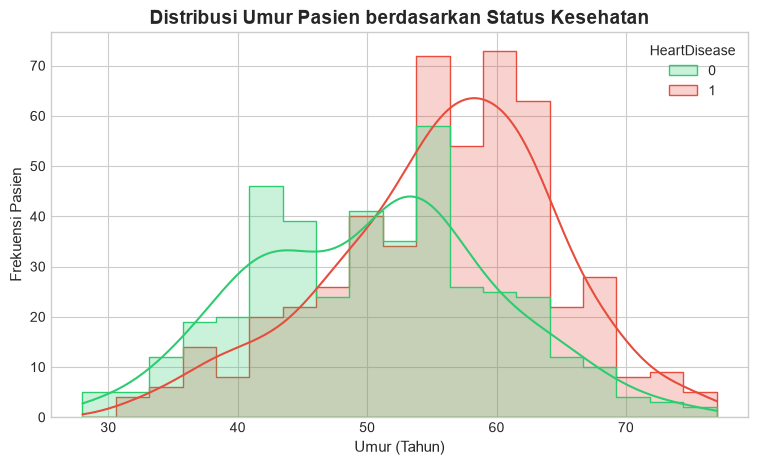

In [7]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Age', hue='HeartDisease', element='step', kde=True, palette=['#2ecc71', '#e74c3c'])
plt.title('Distribusi Umur Pasien berdasarkan Status Kesehatan', fontsize=14, fontweight='bold')
plt.xlabel('Umur (Tahun)', fontsize=11)
plt.ylabel('Frekuensi Pasien', fontsize=11)
plt.show()

### Buat Visualisasi Data Berdasarkan Jenis Kelamin dan Tipe Nyeri Data

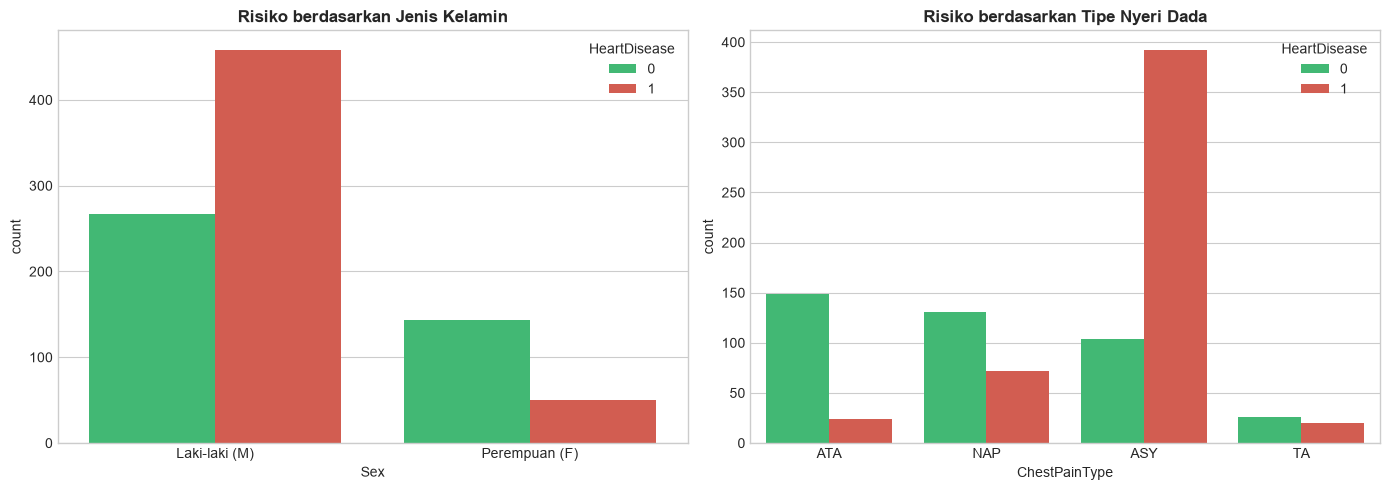

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(ax=axes[0], x='Sex', hue='HeartDisease', data=df, palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Risiko berdasarkan Jenis Kelamin', fontsize=12, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Laki-laki (M)', 'Perempuan (F)'])

sns.countplot(ax=axes[1], x='ChestPainType', hue='HeartDisease', data=df, palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Risiko berdasarkan Tipe Nyeri Dada', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Hapus Column Cholesterol yang bernilai 0

In [9]:
zero_chol = (df['Cholesterol'] == 0).sum()
print(f"Jumlah baris dengan Cholesterol = 0: {zero_chol}")

df = df[df['Cholesterol'] != 0].reset_index(drop=True)

del zero_chol

print(f"Ukuran dataset sekarang: {df.shape}")
print(f"Sisa data Cholesterol = 0: {(df['Cholesterol'] == 0).sum()}")


Jumlah baris dengan Cholesterol = 0: 172
Ukuran dataset sekarang: (746, 12)
Sisa data Cholesterol = 0: 0


### Encoding Data agar menjadi numerikal

In [10]:
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print("Bentuk dataset sebelum encoding:", df.shape)
print("Bentuk dataset setelah encoding:", df_encoded.shape)

df_encoded.head()

Bentuk dataset sebelum encoding: (746, 12)
Bentuk dataset setelah encoding: (746, 16)


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1.0,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0.0,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1.5,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0.0,0,1,0,1,0,1,0,0,0,1


### Buat Matriks Korelasi

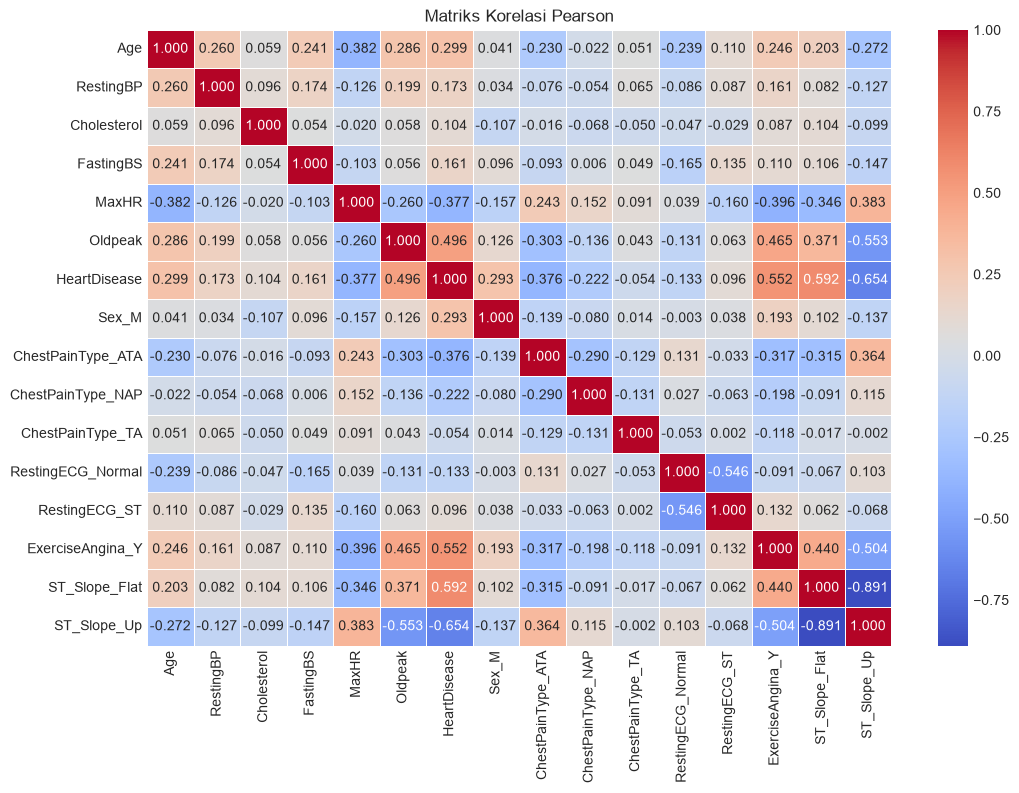

Fitur yang dibuang (korelasi absolut < 0.001): []


In [11]:
corr_matrix = df_encoded.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', linewidths=0.5)
plt.title('Matriks Korelasi Pearson')
plt.show()

target_corr = corr_matrix['HeartDisease'].drop('HeartDisease')

low_corr_features = target_corr[target_corr.abs() < 0.001].index.tolist()
print(f"Fitur yang dibuang (korelasi absolut < 0.001): {low_corr_features}")

df_selected = df_encoded.drop(columns=low_corr_features)

### Memisahkan Data Fitur dengan Target

In [12]:
X = df_encoded.drop(columns=['HeartDisease'])

y = df_encoded['HeartDisease']

print("Ukuran Fitur (X):", X.shape)
print("Ukuran Target (y):", y.shape)

Ukuran Fitur (X): (746, 15)
Ukuran Target (y): (746,)


### Split Data untuk Training dan Testing

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Data Latih (X_train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (X_test)  : {X_test.shape[0]} baris")

Jumlah Data Latih (X_train): 596 baris
Jumlah Data Uji (X_test)  : 150 baris


### Lakukan Standarisasi

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling berhasil dilakukan!")

Feature scaling berhasil dilakukan!


### Latih Model

In [15]:
models = {
    'Logistic Regression': LogisticRegression(),
    'KNN': KNeighborsClassifier()
}

predictions = {}

print("--- Memulai Proses Training Model ---")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    
    print(f"Model [{name}] selesai dilatih!")

--- Memulai Proses Training Model ---
Model [Logistic Regression] selesai dilatih!
Model [KNN] selesai dilatih!


### Print hasil Evaluasi

In [16]:
results_list = []

for name, y_pred in predictions.items():
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

df_results = pd.DataFrame(results_list)
df_results = df_results.sort_values(by='Recall', ascending=False).reset_index(drop=True)

print("--- HASIL PERBANDINGAN 2 MODEL MACHINE LEARNING ---")
df_results

--- HASIL PERBANDINGAN 2 MODEL MACHINE LEARNING ---


,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.866667,0.825000,0.916667,0.868421
1,Logistic Regression,0.853333,0.828947,0.875000,0.851351


### Buat Confusion Matrix dari model dengan akurasi tertinggi 

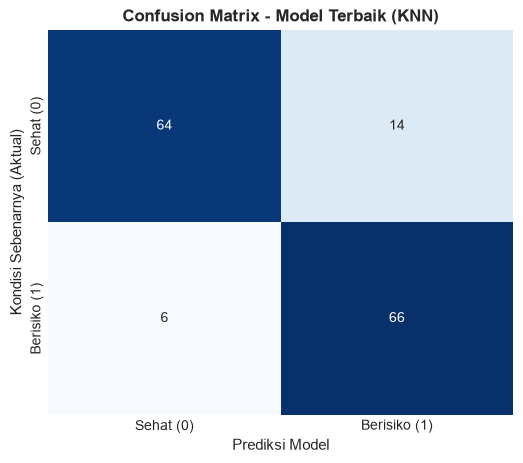


Model Terbaik berdasarkan Recall: KNN
--- Laporan Klasifikasi Lengkap ---
              precision    recall  f1-score   support

           0       0.91      0.82      0.86        78
           1       0.82      0.92      0.87        72

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.87       150
weighted avg       0.87      0.87      0.87       150



In [17]:
best_model_name = df_results.iloc[0]['Model']
best_pred = predictions[best_model_name]

best_model = models[best_model_name]

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Sehat (0)', 'Berisiko (1)'],
            yticklabels=['Sehat (0)', 'Berisiko (1)'])

plt.title(f'Confusion Matrix - Model Terbaik ({best_model_name})', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Kondisi Sebenarnya (Aktual)', fontsize=11)
plt.show()

print(f"\nModel Terbaik berdasarkan Recall: {best_model_name}")

y_pred_best = best_model.predict(X_test_scaled)
print("--- Laporan Klasifikasi Lengkap ---")
print(classification_report(y_test, y_pred_best, zero_division=0))

### Inferensi dari dataset

In [18]:

sample_pasien = X_test.iloc[[0]] 
sample_pasien_scaled = scaler.transform(sample_pasien)

prediksi_hasil = best_model.predict(sample_pasien_scaled)[0]
probabilitas = best_model.predict_proba(sample_pasien_scaled)[0]

print("=== HASIL SIMULASI PREDIKSI PASIEN BARU ===")
print(f"Prediksi Label Target : {prediksi_hasil}")

if prediksi_hasil == 1:
    print(f"DIAGNOSA: PASIEN BERISIKO TERKENA PENYAKIT JANTUNG")
    print(f"Tingkat Keyakinan Model: {probabilitas[1] * 100:.2f}%")
else:
    print(f"DIAGNOSA: PASIEN KONDISI NORMAL / SEHAT")
    print(f"Tingkat Keyakinan Model: {probabilitas[0] * 100:.2f}%")




=== HASIL SIMULASI PREDIKSI PASIEN BARU ===
Prediksi Label Target : 1
DIAGNOSA: PASIEN BERISIKO TERKENA PENYAKIT JANTUNG
Tingkat Keyakinan Model: 100.00%


### Simpan Model ke Folder

In [19]:
joblib.dump(best_model, '../models/heart_disease_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(X.columns.tolist(), '../models/feature_columns.pkl')

print("Model, Scaler, dan Daftar Fitur berhasil disimpan ke folder 'models/'!")

Model, Scaler, dan Daftar Fitur berhasil disimpan ke folder 'models/'!


### Inference dari Inputan User

In [20]:
def inference():
    print("=" * 55)
    print("      FORMULIR INPUT DATA PASIEN BARU (SIMULASI)      ")
    print("=" * 55)
    
    try:
        age = int(input("Masukkan Umur (tahun, contoh: 55): "))
        sex = input("Jenis Kelamin (M = Laki-Laki, F = Perempuan): ").strip().upper()
        while sex not in ['M', 'F']:
            sex = input("Pilihan salah. Masukkan 'M' atau 'F': ").strip().upper()  
        chest_pain = input("Tipe Nyeri Dada (TA, ATA, NAP, ASY): ").strip().upper()
        resting_bp = float(input("Tekanan Darah Istirahat (RestingBP, contoh: 130): "))
        cholesterol = float(input("Kadar Kolesterol (contoh: 220): "))
        fasting_bs = int(input("Gula Darah Puasa > 120 mg/dl? (1 = Ya, 0 = Tidak): "))
        resting_ecg = input("Hasil EKG Istirahat (Normal, ST, LVH): ").strip()
        max_hr = float(input("Detak Jantung Maksimum (MaxHR, contoh: 140): "))
        exercise_angina = input("Angina Saat Olahraga? (Y = Ya, N = Tidak): ").strip().upper()
        oldpeak = float(input("Depresi ST (Oldpeak, contoh: 1.5): "))
        st_slope = input("Kemiringan ST (Up, Flat, Down): ").strip()
        
        data_pasien = {
            'Age': age,
            'Sex': sex,
            'ChestPainType': chest_pain,
            'RestingBP': resting_bp,
            'Cholesterol': cholesterol,
            'FastingBS': fasting_bs,
            'RestingECG': resting_ecg,
            'MaxHR': max_hr,
            'ExerciseAngina': exercise_angina,
            'Oldpeak': oldpeak,
            'ST_Slope': st_slope
        }
        df_input = pd.DataFrame([data_pasien])
        df_input_encoded = pd.get_dummies(df_input)
        df_input_reindexed = df_input_encoded.reindex(columns=X.columns, fill_value=0)
        prediksi = best_model.predict(df_input_reindexed.values)[0]
        
        print("\n" + "=" * 55)
        print("                HASIL DIAGNOSIS MEDIS                ")
        print("=" * 55)
        if prediksi == 1:
            print("STATUS: ⚠️ PASIEN BERISIKO TERKENA PENYAKIT JANTUNG")
            print("Saran : Segera lakukan pemeriksaan laboratorium medis lebih lanjut.")
        else:
            print("STATUS: ✅ PASIEN DIPREDIKSI SEHAT / RISIKO RENDAH")
            print("Saran : Pertahankan pola hidup sehat dan kontrol rutin.")
        print("=" * 55)

    except ValueError:
        print("\n❌ Error: Input tidak valid. Pastikan Anda memasukkan angka untuk variabel numerik!")

inference()

      FORMULIR INPUT DATA PASIEN BARU (SIMULASI)      

❌ Error: Input tidak valid. Pastikan Anda memasukkan angka untuk variabel numerik!
